In [ ]:
from src.functions_generator import FunctionsGenerator
from src.heat1D_crank_nicolson_solver import Heat1DCrankNicolson
from src.print_utils import print_kv, print_section

import time
import h5py
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("styles/plots.mplstyle")
np.random.seed(42)

In [ ]:
#----------------------------------------------------------------------------

total_time = 0

# Parametri simulazione
L = 1
Tf = 10
nt = 5000
D = 1
wanted_r = 0.8
h = 1
l = 0.7
sigma = 1

# Lunghezza FFT per convoluzione lineare corretta.
# La FFT implementa convoluzione circolare: per evitare aliasing
# bisogna fare zero-padding fino a N + M - 1.
# Qui f e risposta impulsiva hanno lunghezza nt dunque n = 2*nt - 1.
n = (2*nt - 1) 

type_used = np.float32

solver = Heat1DCrankNicolson(L,Tf,nt,D,h,wanted_r=wanted_r)
solver.info()

#----------------------------------------------------------------------------

# Di default viene salvata f che corrisponde a nx=0
impulses_indexes = np.array([solver.nx // 2, solver.nx - 1], dtype=np.uint64)

N_impulses = np.size(impulses_indexes)

# Numero di samples
N_f = 10000

lista_f = np.empty((N_f, nt), dtype=type_used)

# Calcolo risorse necessarie
memory_required_bytes = lista_f.nbytes * (N_impulses + 1)

print_section("Dataset info")
print_kv("Number of samples:",N_f)
print_kv("Sample size:",nt)
print_kv("Number of impulses:",N_impulses)

for imp in impulses_indexes:
    print_kv("- Impulse at nx",imp + 1)

print_kv("Total memory required", f"{int(memory_required_bytes/(1024**2))} MB")

#----------------------------------------------------------------------------

print_section("Computing impulse responses")
start = time.time()

lista_trasformata_impulsi = np.empty((N_impulses, nt), dtype=np.complex128)

impulsi = solver.impulse_response()[impulses_indexes]
lista_trasformata_impulsi = np.fft.rfft(impulsi, n)

end = time.time()
total_time = total_time + (end - start)
print_kv("Impulse responses computed", f"{(end - start):.3f} sec")

#----------------------------------------------------------------------------

print_section("Generating left boundary conditions")
start = time.time()

generator = FunctionsGenerator(solver.t_array, l = l, sigma = sigma)

for i in range(N_f):
    lista_f[i] = generator.generate_from_white_noise()

end = time.time()
total_time = total_time + (end - start)
print_kv("Boundary conditions generated", f"{(end - start):.3f} sec")

#----------------------------------------------------------------------------

print_section("Performing convolutions")
start = time.time()

dataset = np.empty((N_f, N_impulses+1, nt), dtype=type_used)

# Correzione trapezoidale per la convoluzione:
# il Crank-Nicolson equivale a un'integrazione con regola dei trapezi,
# quindi la convoluzione discreta usa (f[k] + f[k+1]) / 2.
# Implementato come shift con roll; l'ultimo termine usa solo f[N-1]
# perché si assume f[N] = 0 (zero-padding).
f_trap = np.empty_like(lista_f)
f_trap[:, :-1] = (lista_f[:, :-1] + lista_f[:, 1:]) / 2
f_trap[:, -1] = lista_f[:, -1] / 2

# FFT del segnale corretto (necessaria per convoluzione via prodotto in frequenza)
lista_F = np.fft.rfft(f_trap, n, axis=1)

for i in range(N_f):
    dataset[i,0] = lista_f[i]
    dataset[i,1:] = np.fft.irfft(
        lista_F[i][None, :] * lista_trasformata_impulsi,
        n,
        axis=1
    )[:, :nt] * solver.dt

end = time.time()
total_time = total_time + (end - start)
print_kv("Convolution finished", f"{(end - start):.3f} sec")
print_kv("Average time per sample:", f"{(end - start)/N_f*1000:.3f} ms")

#----------------------------------------------------------------------------

print_section("Saving Dataset")

start = time.time()

with h5py.File("dataset/dataset.h5", "w") as save_file:
    save_file.create_dataset("dataset", data=dataset)

end = time.time()
total_time = total_time + (end - start)
print_kv("Dataset saved", f"{(end - start):.3f} sec")

print_kv("Total Time:", f"{(total_time):.3f} sec")


-----------------------------Solver info------------------------------

Time scale coeff:                                             1.00e+00
dx:                                                           5.00e-02
dt:                                                           2.00e-03
nt:                                                               5000
nx:                                                                 21
r:                                                            8.00e-01
h:                                                            1.00e+00

-----------------------------Dataset info-----------------------------

Number of samples:                                               10000
Sample size:                                                      5000
Number of impulses:                                                  2
- Impulse at nx                                                     11
- Impulse at nx                                                     21
To

Squared distance: 2.0742668318122655e-06
Squared distance: 1.4951339874042726e-06


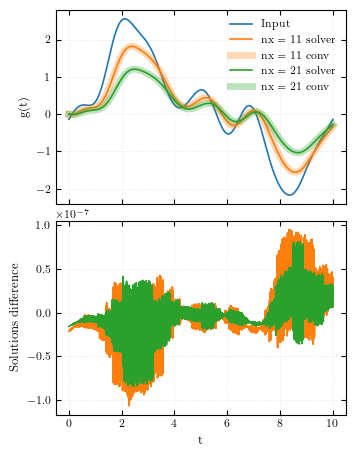

In [4]:
# Verifica funzionamento
fig, axes = plt.subplots(2,1,figsize=(3.4, 4.4), sharex=True)

f_test = dataset[0,0]
T = solver.solve(f_test)
axes[0].plot(solver.t_array,f_test,label="Input", color="C0")
for i in range(N_impulses):
    g_solver_tmp = T[impulses_indexes[i], :]
    axes[0].plot(solver.t_array, g_solver_tmp, color=f"C{i+1}", label=f"nx = {impulses_indexes[i] + 1} solver")
    axes[0].plot(solver.t_array, dataset[0,i+1], lw=5,alpha=0.3, color=f"C{i+1}", label=f"nx = {impulses_indexes[i] + 1} conv")
    axes[0].legend()

    print(f"Squared distance: {np.linalg.norm(dataset[0,i+1,:]-g_solver_tmp[:])}")
    axes[1].plot(solver.t_array,(dataset[0,i+1,:]-g_solver_tmp[:]), color=f"C{i+1}")
    axes[1].set_ylabel("Solutions difference")
    
axes[0].grid()
axes[1].grid()
axes[1].set_xlabel("t")
axes[0].set_ylabel("g(t)")

plt.show()